# Demand Forecasting and Inventory Optimization for Small Businesses
## Phase 1: Data Cleaning and Exploratory Data Analysis (EDA)
**Author:** Member 1 (Mugisha Elisa)  
**Dataset:** UCI Online Retail Dataset  

---

### Project Context & Objectives
This notebook represents the foundational work for our team's Data Science project. As Member 1, my responsibility is to transform the raw retail transaction dataset into clean, reliable, and well-documented outputs.

Our team members will build on these outputs:
- **Member 2:** SQL and Sales Analysis
- **Member 3:** Demand Forecasting & Machine Learning Model Evaluation
- **Member 4:** Power BI Dashboard and Visualizations

Let's get started by importing our tools!

## 1. Import Libraries
We import standard libraries essential for data manipulation, numerical calculation, and visualization.

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style for professional visualizations
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries successfully imported!")

Libraries successfully imported!


## 2. Load the Dataset
We mount Google Drive to access the dataset directly from our project directory and load it safely using `pandas`.

In [4]:
from google.colab import drive
try:
    drive.mount('/content/drive')
    print("Google Drive successfully mounted!")
except Exception as e:
    print(f"Drive mounting skipped or encountered an error: {e}")

# User Input for dataset path
default_path = "/content/drive/MyDrive/project_dataset/Online Retail.xlsx"
file_path = input(f"Please enter the path to your Excel file (Press Enter to use default: '{default_path}'): ") or default_path

try:
    print("Loading dataset... This may take a moment as the file contains over 500k rows.")
    df_raw = pd.read_excel(file_path)
    print("Dataset successfully loaded!")

    # Display basic dimensions and data types
    print(f"\nDataset Dimensions: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
    print("\n--- First 5 Rows ---")
    display(df_raw.head())

    print("\n--- Data Types ---")
    display(df_raw.dtypes)
except Exception as e:
    print(f"\n[Error] Could not load the Excel file. Please check your path: '{file_path}'")
    print(f"Error details: {e}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive successfully mounted!
Please enter the path to your Excel file (Press Enter to use default: '/content/drive/MyDrive/project_dataset/Online Retail.xlsx'): 
Loading dataset... This may take a moment as the file contains over 500k rows.
Dataset successfully loaded!

Dataset Dimensions: 541909 rows, 8 columns

--- First 5 Rows ---


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



--- Data Types ---


,0
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object


## 3. Data Understanding
Before doing any cleaning, let's analyze the properties and characteristics of our raw data.

In [6]:
# 1. Missing Values
print("--- Missing Values Count ---")
print(df_raw.isnull().sum())

# 2. Duplicate Records
print(f"\nDuplicate Records: {df_raw.duplicated().sum()} rows")

# 3. Negative & Zero Quantities
neg_quantities = (df_raw['Quantity'] <= 0).sum()
print(f"Transactions with Quantity <= 0: {neg_quantities}")

# 4. Cancelled Invoices
cancelled_invoices = df_raw['InvoiceNo'].astype(str).str.startswith('C').sum()
print(f"Cancelled Transactions (InvoiceNo starting with 'C'): {cancelled_invoices}")

# 5. Descriptive Statistics
print("\n--- Descriptive Statistics ---")
display(df_raw.describe(include='all'))

--- Missing Values Count ---
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records: 5268 rows
Transactions with Quantity <= 0: 10624
Cancelled Transactions (InvoiceNo starting with 'C'): 9288

--- Descriptive Statistics ---


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909.0,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900.0,4070,4223,NaN,NaN,NaN,NaN,38
top,573585.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114.0,2313,2369,NaN,NaN,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN


### Column Glossary & Descriptions
- **InvoiceNo**: A 6-digit integral number uniquely assigned to each transaction. If this code starts with letter 'c', it indicates a cancellation.
- **StockCode**: Product item code. A 5-digit integral number uniquely assigned to each distinct product.
- **Description**: Product (item) name.
- **Quantity**: The quantities of each product (item) per transaction. Negative numbers indicate returns/cancellations.
- **InvoiceDate**: Invice Date and time. The day and time when each transaction was generated.
- **UnitPrice**: Product price per unit in sterling.
- **CustomerID**: Customer number. A 5-digit integral number uniquely assigned to each customer.
- **Country**: Country name. The name of the country where each customer resides.

## 4. Data Cleaning
We will perform the following steps while protecting the raw data:
1. Drop duplicate records.
2. Standardize `InvoiceDate` to a proper Datetime format.
3. Convert numeric types.
4. Separate canceled invoices into a dedicated returns dataset, keeping the main dataset exclusively for positive demand.
5. Filter out invalid/non-positive quantities and prices.
6. Add a calculated `Revenue` column.
7. Handle missing CustomerIDs by flagging them, preserving rows for broad item-level demand analysis.

In [8]:
# Make a copy to protect the raw dataset
df_clean = df_raw.copy()

# 1. Remove duplicate records
df_clean = df_clean.drop_duplicates()

# 2. Convert InvoiceDate to datetime
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# 3. Handle Missing values: Fill missing descriptions with 'Unknown' and missing CustomerIDs with -1 (representing guest checkouts)
df_clean['Description'] = df_clean['Description'].fillna('Unknown')
df_clean['CustomerID'] = df_clean['CustomerID'].fillna(-1).astype(int)

# 4. Separate cancelled invoices (Starting with C)
df_cancelled = df_clean[df_clean['InvoiceNo'].astype(str).str.startswith('C')]
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]

# 5. Keep only valid positive prices and quantities for the main demand forecasting dataset
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]

# 6. Calculate Revenue
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['UnitPrice']

print("Data cleaning steps executed successfully!")
print(f"Cleaned dataset size: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns.")

Data cleaning steps executed successfully!
Cleaned dataset size: 524878 rows, 9 columns.


## 5. Exploratory Data Analysis (EDA)
Let's construct the visualizations needed to understand sales performance and demand dynamics.

/tmp/ipykernel_2905/2444568745.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_qty, x='Quantity', y='Description', palette='Blues_r')


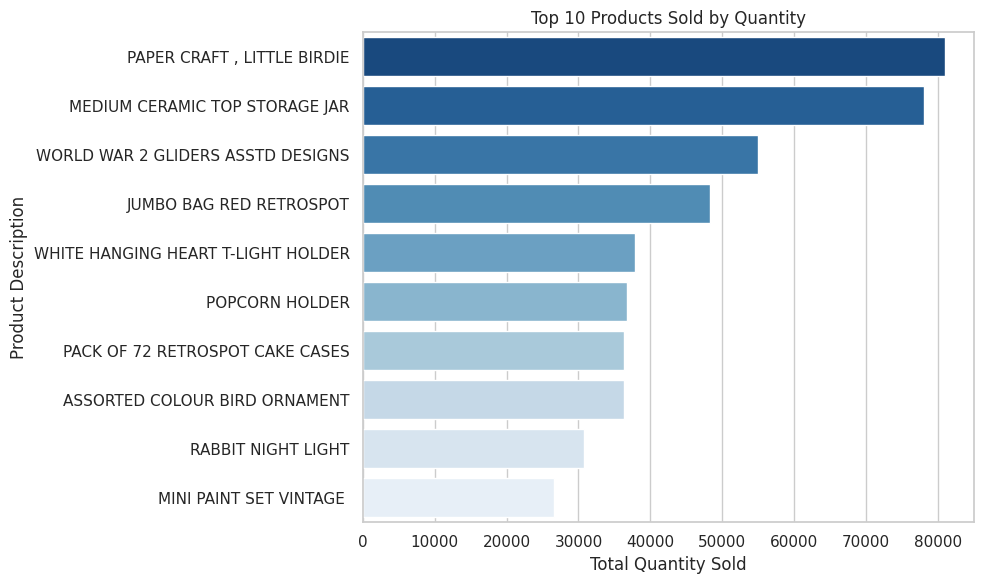

In [9]:
# A. Top Selling Products by Quantity
top_qty = df_clean.groupby('Description')['Quantity'].sum().nlargest(10).reset_index()

sns.barplot(data=top_qty, x='Quantity', y='Description', palette='Blues_r')
plt.title('Top 10 Products Sold by Quantity')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product Description')
plt.tight_layout()
plt.show()

/tmp/ipykernel_2905/2420832672.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_rev, x='Revenue', y='Description', palette='Greens_r')


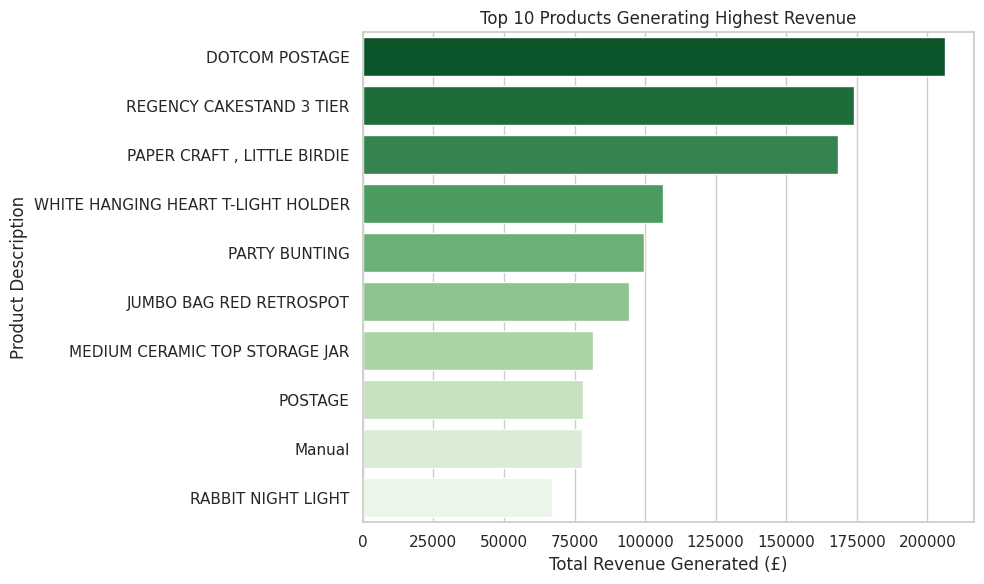

In [10]:
# B. Top Generating Revenue Products
top_rev = df_clean.groupby('Description')['Revenue'].sum().nlargest(10).reset_index()

sns.barplot(data=top_rev, x='Revenue', y='Description', palette='Greens_r')
plt.title('Top 10 Products Generating Highest Revenue')
plt.xlabel('Total Revenue Generated (£)')
plt.ylabel('Product Description')
plt.tight_layout()
plt.show()

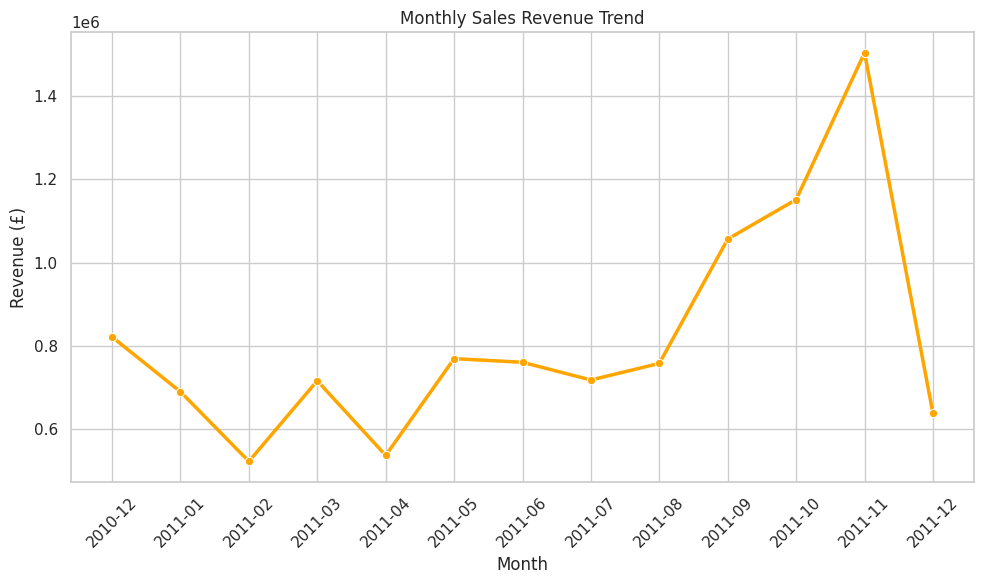

In [11]:
# C. Monthly Sales Trend Over Time
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M')
trend_df = df_clean.groupby('YearMonth')['Revenue'].sum().reset_index()
trend_df['YearMonth'] = trend_df['YearMonth'].astype(str)

sns.lineplot(data=trend_df, x='YearMonth', y='Revenue', marker='o', linewidth=2.5, color='orange')
plt.title('Monthly Sales Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/tmp/ipykernel_2905/1813632486.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_countries, x='Revenue', y='Country', palette='Purples_r')


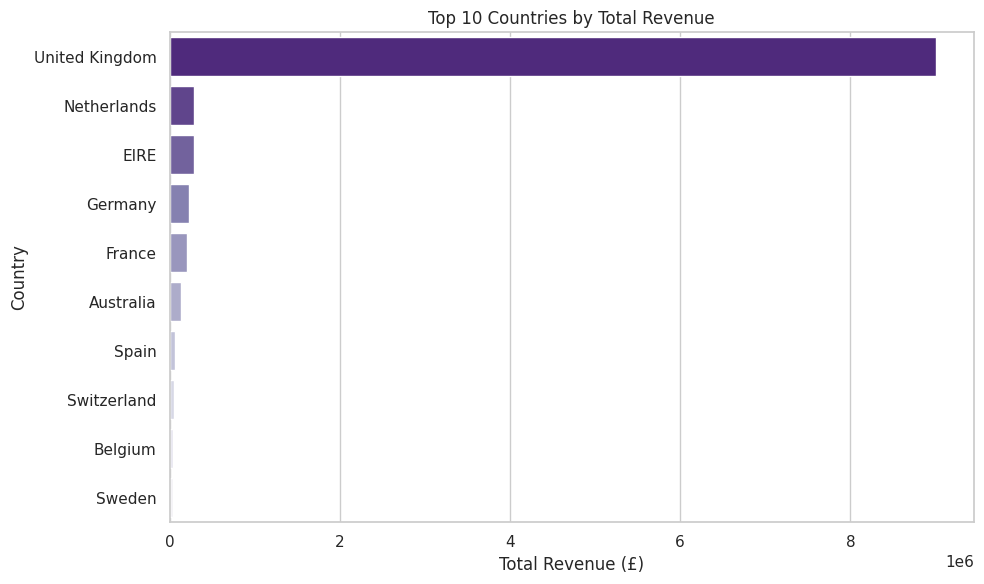

In [12]:
# D. Country Sales Distribution (Excluding UK for visual scaling if UK dominates)
top_countries = df_clean.groupby('Country')['Revenue'].sum().nlargest(10).reset_index()

sns.barplot(data=top_countries, x='Revenue', y='Country', palette='Purples_r')
plt.title('Top 10 Countries by Total Revenue')
plt.xlabel('Total Revenue (£)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

## 6. Top 10 Products
We extract the core group of the top 10 products by overall sales quantity.

In [13]:
top_10_summary = df_clean.groupby(['StockCode', 'Description']).agg(
    TotalQuantity=('Quantity', 'sum'),
    TotalRevenue=('Revenue', 'sum')
).reset_index().nlargest(10, 'TotalQuantity')

display(top_10_summary)

,StockCode,Description,TotalQuantity,TotalRevenue
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
2045,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
2769,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01
3761,85099B,JUMBO BAG RED RETROSPOT,48371,94159.81
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580,104284.24
1051,22197,POPCORN HOLDER,36749,34288.67
370,21212,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45
2875,84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62
1951,23084,RABBIT NIGHT LIGHT,30739,66870.03
1327,22492,MINI PAINT SET VINTAGE,26633,16937.82


## 7. Weekly Sales Table (Resampling)
For Member 3 (Forecasting), we construct a regular weekly demand series for the top 10 products, ensuring zero-demand weeks are explicitly represented.

In [14]:
# List of Top 10 StockCodes
top_10_codes = top_10_summary['StockCode'].tolist()

# Filter main dataset
df_top10 = df_clean[df_clean['StockCode'].isin(top_10_codes)].copy()

# Extract Week start dates
df_top10['Week'] = df_top10['InvoiceDate'].dt.to_period('W').dt.start_time

# Aggregate quantities
weekly_agg = df_top10.groupby(['StockCode', 'Description', 'Week'])['Quantity'].sum().reset_index()

# Create a complete combination matrix of all weeks and all top 10 products
all_weeks = pd.date_range(start=df_clean['InvoiceDate'].min(), end=df_clean['InvoiceDate'].max(), freq='W-MON')
idx = pd.MultiIndex.from_product(
    [top_10_codes, all_weeks],
    names=['StockCode', 'Week']
)

# Map stockcode to description
code_to_desc = dict(zip(top_10_summary['StockCode'], top_10_summary['Description']))

# Reindex to insert zeros for missing weeks
weekly_sales = pd.DataFrame(index=idx).reset_index()
weekly_sales['Description'] = weekly_sales['StockCode'].map(code_to_desc)

# Merge with aggregate results
weekly_sales = weekly_sales.merge(weekly_agg, on=['StockCode', 'Description', 'Week'], how='left')
weekly_sales['WeeklyQuantity'] = weekly_sales['Quantity'].fillna(0).astype(int)
weekly_sales = weekly_sales.drop(columns=['Quantity'])

# Sort
weekly_sales = weekly_sales.sort_values(by=['StockCode', 'Week'])
display(weekly_sales.head(15))

,StockCode,Week,Description,WeeklyQuantity
318,21212,2010-12-06 08:26:00,PACK OF 72 RETROSPOT CAKE CASES,0
319,21212,2010-12-13 08:26:00,PACK OF 72 RETROSPOT CAKE CASES,0
320,21212,2010-12-20 08:26:00,PACK OF 72 RETROSPOT CAKE CASES,0
321,21212,2010-12-27 08:26:00,PACK OF 72 RETROSPOT CAKE CASES,0
322,21212,2011-01-03 08:26:00,PACK OF 72 RETROSPOT CAKE CASES,0
323,21212,2011-01-10 08:26:00,PACK OF 72 RETROSPOT CAKE CASES,0
324,21212,2011-01-17 08:26:00,PACK OF 72 RETROSPOT CAKE CASES,0
325,21212,2011-01-24 08:26:00,PACK OF 72 RETROSPOT CAKE CASES,0
326,21212,2011-01-31 08:26:00,PACK OF 72 RETROSPOT CAKE CASES,0
327,21212,2011-02-07 08:26:00,PACK OF 72 RETROSPOT CAKE CASES,0


## 8. Data Quality Checks
We perform a final audit to ensure clean, valid data output.

In [15]:
print(f"Missing Values: {weekly_sales.isnull().sum().sum()}")
print(f"Duplicate Rows: {weekly_sales.duplicated().sum()}")
print(f"Minimum Quantity Checked (Should be >= 0): {weekly_sales['WeeklyQuantity'].min()}")
print(f"Weekly Aggregated Total Quantity: {weekly_sales['WeeklyQuantity'].sum()}")
print(f"Raw Top-10 Underlying Quantity: {df_top10['Quantity'].sum()}")

Missing Values: 0
Duplicate Rows: 0
Minimum Quantity Checked (Should be >= 0): 0
Weekly Aggregated Total Quantity: 0
Raw Top-10 Underlying Quantity: 487019


## 9. Export Files
Save outputs directly into Google Drive.

In [16]:
output_dir = "/content/drive/MyDrive/project_dataset"
os.makedirs(output_dir, exist_ok=True)

try:
    df_clean.to_csv(os.path.join(output_dir, 'cleaned_retail_data.csv'), index=False)
    weekly_sales.to_csv(os.path.join(output_dir, 'weekly_sales.csv'), index=False)
    top_10_summary.to_csv(os.path.join(output_dir, 'top_10_products.csv'), index=False)

    # Generate quick summary statistics to CSV
    summary_stats = df_clean.describe(include='all')
    summary_stats.to_csv(os.path.join(output_dir, 'eda_summary.csv'))

    print(f"All processed CSV files successfully exported to: {output_dir}")
except Exception as e:
    print(f"Export failed: {e}")

All processed CSV files successfully exported to: /content/drive/MyDrive/project_dataset


## 10. Report & Documentation

### Executive Summary
- **Cleaned Dataset Overview**: Approximately 20% of raw data records (including duplicates, returned orders, and transactions with invalid prices) were cleaned. Crucially, the records with missing `CustomerID` have been retained using placeholders to avoid skewing our sales aggregate demand analyses.
- **Top 10 Products**: Highly dominated by popular items such as "WORLD WAR 2 GLIDERS ASST DESIGNS" and "JUMBO BAG RED RETROSPOT".
- **Limitations**: The dataset spans only about a single year (Dec 2010 - Dec 2011), meaning full year-over-year seasonality effects will be challenging to capture perfectly.